In [1]:
from IPython.display import clear_output
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import networkx as nx
from scipy.spatial.distance import squareform

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader


import warnings
warnings.simplefilter(action='ignore', category=Warning)

In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

clear_output()

In [3]:
dictionary = pd.read_excel('/kaggle/input/widsdatathon2025/Data Dictionary.xlsx')

training_solution = pd.read_excel('/kaggle/input/widsdatathon2025/TRAIN_NEW/TRAINING_SOLUTIONS.xlsx')
train_functional_connectome = pd.read_csv('/kaggle/input/widsdatathon2025/TRAIN_NEW/TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv')
train_categorical_data = pd.read_excel('/kaggle/input/widsdatathon2025/TRAIN_NEW/TRAIN_CATEGORICAL_METADATA_new.xlsx')
train_quantitative_data = pd.read_excel('/kaggle/input/widsdatathon2025/TRAIN_NEW/TRAIN_QUANTITATIVE_METADATA_new.xlsx')

test_functional_connectome = pd.read_csv('/kaggle/input/widsdatathon2025/TEST/TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv')
test_categorical_data = pd.read_excel('/kaggle/input/widsdatathon2025/TEST/TEST_CATEGORICAL.xlsx')
test_quantitative_data = pd.read_excel('/kaggle/input/widsdatathon2025/TEST/TEST_QUANTITATIVE_METADATA.xlsx')
sample_submission = pd.read_excel('/kaggle/input/widsdatathon2025/SAMPLE_SUBMISSION.xlsx')

## EDA

### examples of brain imaging sample

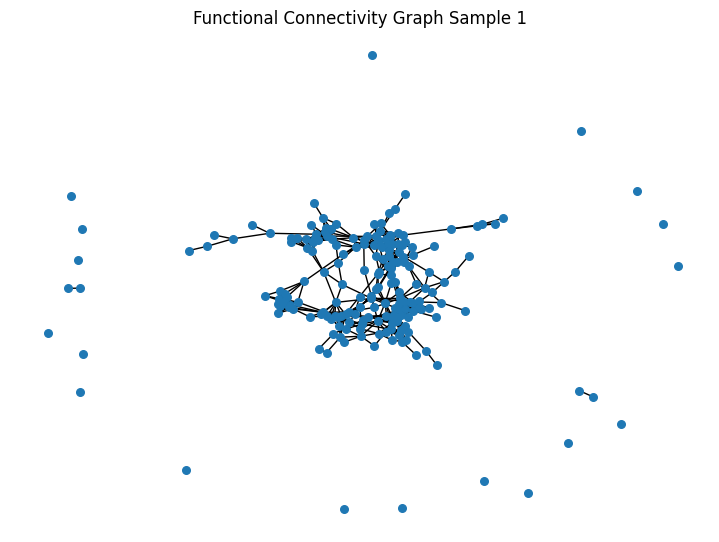

In [4]:
upper_tri_flat = train_functional_connectome.iloc[0, 1:]
conn_matrix = squareform(upper_tri_flat)
np.fill_diagonal(conn_matrix, 0)

threshold = 0.5
conn_thresh = (conn_matrix > threshold).astype(int)

graph = nx.from_numpy_array(conn_thresh)

plt.figure(figsize=(7, 5))
nx.draw_spring(graph, node_size=30, with_labels=False)
plt.title("Functional Connectivity Graph Sample 1")
plt.show()

In [5]:
train_quantitative_data.describe().T[:]

,count,mean,std,min,25%,50%,75%,max
EHQ_EHQ_Total,1200.0,59.514750,49.744631,-100.0,46.670000,77.800000,94.470000,100.000000
ColorVision_CV_Score,1190.0,13.419328,2.112830,0.0,14.000000,14.000000,14.000000,14.000000
APQ_P_APQ_P_CP,1201.0,3.819317,1.330348,2.0,3.000000,3.000000,4.000000,12.000000
APQ_P_APQ_P_ID,1201.0,13.337219,3.593562,5.0,11.000000,13.000000,16.000000,28.000000
APQ_P_APQ_P_INV,1201.0,39.767694,4.872729,23.0,36.000000,40.000000,43.000000,50.000000
APQ_P_APQ_P_OPD,1201.0,17.963364,3.333965,7.0,16.000000,18.000000,20.000000,28.000000
APQ_P_APQ_P_PM,1201.0,16.557036,5.146548,5.0,13.000000,16.000000,19.000000,37.000000
APQ_P_APQ_P_PP,1201.0,25.498751,3.053720,13.0,23.000000,26.000000,28.000000,30.000000
SDQ_SDQ_Conduct_Problems,1204.0,2.074751,2.022992,0.0,0.000000,2.000000,3.000000,10.000000
SDQ_SDQ_Difficulties_Total,1204.0,12.213455,6.517330,0.0,7.000000,12.000000,17.000000,34.000000


In [6]:
train_quantitative_data.shape

(1213, 19)

### let us merge the quantitative and categorical data

In [7]:
train_quant_cat = pd.merge(train_categorical_data, train_quantitative_data, on='participant_id', how='inner')
test_quant_cat = pd.merge(test_categorical_data, test_quantitative_data, on='participant_id', how='inner')

### Before filling null values

In [8]:
train_quant_cat.isnull().sum()

participant_id                        0
Basic_Demos_Enroll_Year               0
Basic_Demos_Study_Site                0
PreInt_Demos_Fam_Child_Ethnicity     43
PreInt_Demos_Fam_Child_Race          54
MRI_Track_Scan_Location               3
Barratt_Barratt_P1_Edu               15
Barratt_Barratt_P1_Occ               31
Barratt_Barratt_P2_Edu              198
Barratt_Barratt_P2_Occ              222
EHQ_EHQ_Total                        13
ColorVision_CV_Score                 23
APQ_P_APQ_P_CP                       12
APQ_P_APQ_P_ID                       12
APQ_P_APQ_P_INV                      12
APQ_P_APQ_P_OPD                      12
APQ_P_APQ_P_PM                       12
APQ_P_APQ_P_PP                       12
SDQ_SDQ_Conduct_Problems              9
SDQ_SDQ_Difficulties_Total            9
SDQ_SDQ_Emotional_Problems            9
SDQ_SDQ_Externalizing                 9
SDQ_SDQ_Generating_Impact             9
SDQ_SDQ_Hyperactivity                 9
SDQ_SDQ_Internalizing                 9


In [9]:
test_quant_cat.isnull().sum()

participant_id                       0
Basic_Demos_Enroll_Year              0
Basic_Demos_Study_Site               0
PreInt_Demos_Fam_Child_Ethnicity     3
PreInt_Demos_Fam_Child_Race          6
MRI_Track_Scan_Location              0
Barratt_Barratt_P1_Edu               1
Barratt_Barratt_P1_Occ               1
Barratt_Barratt_P2_Edu              36
Barratt_Barratt_P2_Occ              42
EHQ_EHQ_Total                        1
ColorVision_CV_Score                 9
APQ_P_APQ_P_CP                      15
APQ_P_APQ_P_ID                      15
APQ_P_APQ_P_INV                     15
APQ_P_APQ_P_OPD                     15
APQ_P_APQ_P_PM                      15
APQ_P_APQ_P_PP                      15
SDQ_SDQ_Conduct_Problems            30
SDQ_SDQ_Difficulties_Total          30
SDQ_SDQ_Emotional_Problems          30
SDQ_SDQ_Externalizing               30
SDQ_SDQ_Generating_Impact           30
SDQ_SDQ_Hyperactivity               30
SDQ_SDQ_Internalizing               30
SDQ_SDQ_Peer_Problems    

### After filling null values with median values

In [10]:
# write in paper why you chose median for data imputation
train_quant_cat.fillna(train_quant_cat.median(numeric_only=True), inplace=True)
test_quant_cat.fillna(test_quant_cat.median(numeric_only=True), inplace=True)

In [11]:
train_quant_cat.isnull().sum()

participant_id                      0
Basic_Demos_Enroll_Year             0
Basic_Demos_Study_Site              0
PreInt_Demos_Fam_Child_Ethnicity    0
PreInt_Demos_Fam_Child_Race         0
MRI_Track_Scan_Location             0
Barratt_Barratt_P1_Edu              0
Barratt_Barratt_P1_Occ              0
Barratt_Barratt_P2_Edu              0
Barratt_Barratt_P2_Occ              0
EHQ_EHQ_Total                       0
ColorVision_CV_Score                0
APQ_P_APQ_P_CP                      0
APQ_P_APQ_P_ID                      0
APQ_P_APQ_P_INV                     0
APQ_P_APQ_P_OPD                     0
APQ_P_APQ_P_PM                      0
APQ_P_APQ_P_PP                      0
SDQ_SDQ_Conduct_Problems            0
SDQ_SDQ_Difficulties_Total          0
SDQ_SDQ_Emotional_Problems          0
SDQ_SDQ_Externalizing               0
SDQ_SDQ_Generating_Impact           0
SDQ_SDQ_Hyperactivity               0
SDQ_SDQ_Internalizing               0
SDQ_SDQ_Peer_Problems               0
SDQ_SDQ_Pros

In [12]:
test_quant_cat.isnull().sum()

participant_id                      0
Basic_Demos_Enroll_Year             0
Basic_Demos_Study_Site              0
PreInt_Demos_Fam_Child_Ethnicity    0
PreInt_Demos_Fam_Child_Race         0
MRI_Track_Scan_Location             0
Barratt_Barratt_P1_Edu              0
Barratt_Barratt_P1_Occ              0
Barratt_Barratt_P2_Edu              0
Barratt_Barratt_P2_Occ              0
EHQ_EHQ_Total                       0
ColorVision_CV_Score                0
APQ_P_APQ_P_CP                      0
APQ_P_APQ_P_ID                      0
APQ_P_APQ_P_INV                     0
APQ_P_APQ_P_OPD                     0
APQ_P_APQ_P_PM                      0
APQ_P_APQ_P_PP                      0
SDQ_SDQ_Conduct_Problems            0
SDQ_SDQ_Difficulties_Total          0
SDQ_SDQ_Emotional_Problems          0
SDQ_SDQ_Externalizing               0
SDQ_SDQ_Generating_Impact           0
SDQ_SDQ_Hyperactivity               0
SDQ_SDQ_Internalizing               0
SDQ_SDQ_Peer_Problems               0
SDQ_SDQ_Pros

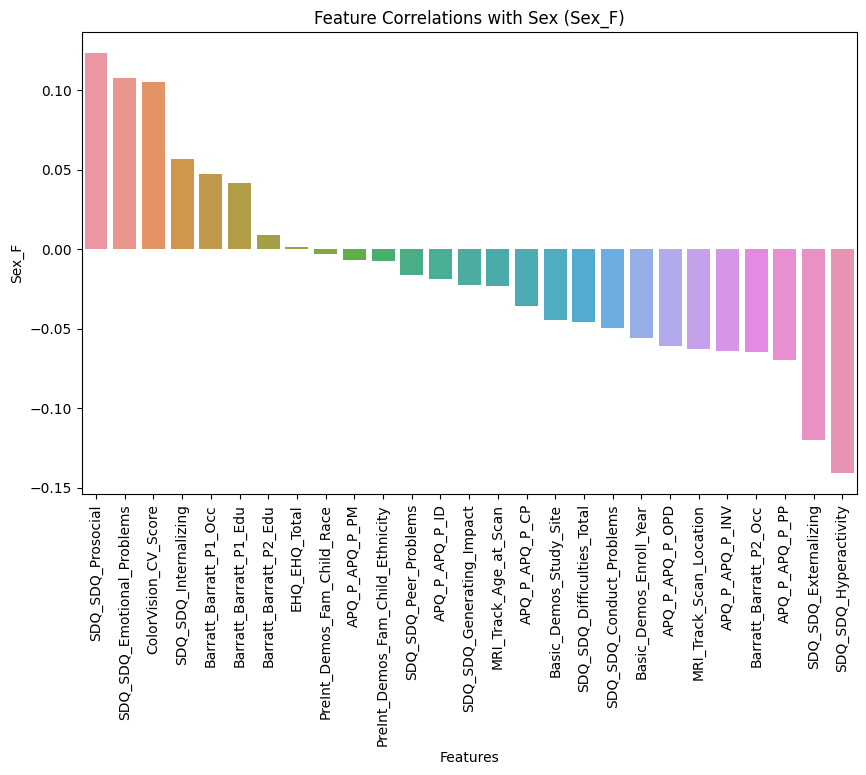

In [13]:
corr_map = pd.merge(training_solution, train_quant_cat, on="participant_id", how="inner")
corr_map = corr_map.drop(['participant_id', 'ADHD_Outcome'], axis=1).corr()
correlation_with_sex = corr_map['Sex_F'].drop('Sex_F').sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=correlation_with_sex.index, y=correlation_with_sex.values)
plt.xlabel("Features")
plt.xticks(rotation=90)
plt.ylabel("Sex_F")
plt.title("Feature Correlations with Sex (Sex_F)")
plt.show()

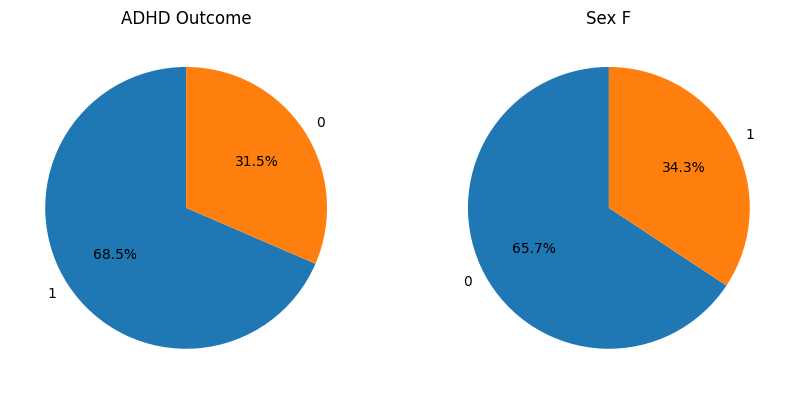

In [14]:
fig, axs = plt.subplots(1,2, figsize=(10,7))

for col, ax in zip(training_solution.drop('participant_id',axis=1), axs):    
    counts = training_solution[col].value_counts()
    ax.pie(counts, labels=counts.index, 
           autopct='%1.1f%%', 
           startangle=90)
    ax.set_title(f'{col.split("_")[0]} {col.split("_")[1]}')

there is an imbalance in classes, which arises when the number of observations belonging to one class is lower than the other. Ensemble learning can be used to combat this by combining multiple models to obtain a robust model, and can be used with data augmentation methods to address class imbalance problems. We will address this later when we come to hyperparameter tune our model.

## Merging quantitative, categorical and connectome data

In [15]:
train_conn_solution = pd.merge(train_quant_cat,train_functional_connectome, on='participant_id', how='inner')
test_conn_solution = pd.merge(test_quant_cat,test_functional_connectome, on='participant_id', how='inner')

In [16]:
train_conn_solution.drop('participant_id', axis=1, inplace=True)
test_conn_solution.drop('participant_id', axis=1, inplace=True)
training_solution.drop('participant_id', axis=1, inplace=True)

In [17]:
X_train, X_val, y_train, y_val = train_test_split(train_conn_solution, training_solution, test_size=0.2, random_state=42, shuffle=True)

In [18]:
print('---train test split---')
print('X train:', X_train.shape) 
print('X val:', X_val.shape)

---train test split---
X train: (970, 19927)
X val: (243, 19927)


## Building Tree-Based Models

### scaling the data

In [19]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
y_train = y_train.to_numpy().astype(float)

### applying PCA

In [18]:
pca = PCA(n_components=0.95)

X_train_reduced = pca.fit_transform(X_train)
X_val_reduced = pca.transform(X_val)

print("Reduced shape:", X_train_reduced.shape)

Reduced shape: (970, 750)


### xgboost model

In [20]:
# without PCA
print('training xgboost model...')
xgb_model = MultiOutputClassifier(xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42))
xgb_model.fit(X_train,y_train)
print('training complete.')

training xgboost model...
training complete.


In [21]:
print('----------XGBOOST MODEL METRICS--------------')
y_pred = xgb_model.predict(X_val)
print(classification_report(y_val, y_pred))

----------XGBOOST MODEL METRICS--------------
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       161
           1       0.30      0.34      0.32        79

   micro avg       0.56      0.78      0.66       240
   macro avg       0.48      0.67      0.56       240
weighted avg       0.54      0.78      0.64       240
 samples avg       0.59      0.67      0.60       240



In [22]:
print('training xgboost model with PCA...')
xgb_model_PCA = MultiOutputClassifier(xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42))
xgb_model_PCA.fit(X_train_reduced,y_train)
print('training complete.')

training xgboost model with PCA...
training complete.


In [24]:
print('----------XGBOOST MODEL WITH PCA METRICS--------------')
y_pred = xgb_model_PCA.predict(X_val_reduced)
print(classification_report(y_val, y_pred))

----------XGBOOST MODEL WITH PCA METRICS--------------
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       161
           1       0.00      0.00      0.00        79

   micro avg       0.66      0.67      0.67       240
   macro avg       0.33      0.50      0.40       240
weighted avg       0.44      0.67      0.53       240
 samples avg       0.66      0.58      0.61       240



### random forest model

In [25]:
print('training random forest model...')
rf_model = MultiOutputClassifier(RandomForestClassifier(criterion='log_loss', random_state=42))
rf_model.fit(X_train,y_train)
print('training complete.')

training random forest model...
training complete.


In [26]:
print('----------RANDOM FOREST MODEL METRICS--------------')
y_pred = rf_model.predict(X_val)
print(classification_report(y_val, y_pred))

----------RANDOM FOREST MODEL METRICS--------------
              precision    recall  f1-score   support

           0       0.65      0.94      0.77       161
           1       0.00      0.00      0.00        79

   micro avg       0.65      0.63      0.64       240
   macro avg       0.33      0.47      0.39       240
weighted avg       0.44      0.63      0.52       240
 samples avg       0.62      0.55      0.57       240



In [27]:
print('training random forest model with PCA...')
rf_model_PCA = MultiOutputClassifier(RandomForestClassifier(criterion='log_loss', random_state=42))
rf_model_PCA.fit(X_train_reduced,y_train)
print('training complete.')

training randome forest model with PCA...
training complete.


In [28]:
print('----------RANDOM FOREST MODEL METRICS WITH PCA--------------')
y_pred = rf_model_PCA.predict(X_val_reduced)
print(classification_report(y_val, y_pred))

----------RANDOM FOREST MODEL METRICS WITH PCA--------------
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       161
           1       0.32      0.99      0.49        79

   micro avg       0.49      1.00      0.66       240
   macro avg       0.49      0.99      0.64       240
weighted avg       0.55      1.00      0.69       240
 samples avg       0.49      0.82      0.60       240



### gradient boosting model

In [32]:
from sklearn.ensemble import GradientBoostingClassifier
print('training gradient boosting model...')
gb_model = MultiOutputClassifier(GradientBoostingClassifier(loss='log_loss', learning_rate=0.01, random_state=42))
gb_model.fit(X_train,y_train)
print('training complete.')

training gradient boosting model...
training complete.


In [33]:
print('----------GRADIENT BOOSTING MODEL METRICS--------------')
y_pred = gb_model.predict(X_val)
print(classification_report(y_val, y_pred))

----------GRADIENT BOOSTING MODEL METRICS--------------
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       161
           1       0.50      0.03      0.05        79

   micro avg       0.66      0.68      0.67       240
   macro avg       0.58      0.51      0.42       240
weighted avg       0.61      0.68      0.55       240
 samples avg       0.66      0.59      0.61       240



In [34]:
print('training gradient boost model with PCA...')
gb_model_PCA = MultiOutputClassifier(GradientBoostingClassifier(loss='log_loss', learning_rate=0.01, random_state=42))
gb_model_PCA.fit(X_train_reduced,y_train)
print('training complete.')

training gradient boost model with PCA...
training complete.


In [35]:
print('----------GRADIENT BOOSTING MODEL WITH PCA METRICS--------------')
y_pred = gb_model_PCA.predict(X_val_reduced)
print(classification_report(y_val, y_pred))

----------GRADIENT BOOSTING MODEL WITH PCA METRICS--------------
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       161
           1       0.00      0.00      0.00        79

   micro avg       0.66      0.67      0.67       240
   macro avg       0.33      0.50      0.40       240
weighted avg       0.44      0.67      0.53       240
 samples avg       0.66      0.58      0.61       240



## Artifical Neural Network Approach (ANN)

In [71]:
class MultiTaskANN(nn.Module):
    def __init__(self, input_dim=19927, hidden_dim=128, dropout=0.3):
        super().__init__()

        self.shared_fc1 = nn.Linear(input_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)

        self.adhd_head = nn.Linear(hidden_dim, 1)
        self.sex_head = nn.Linear(hidden_dim, 1)
    
    def forward(self, x):
        x = F.relu(self.shared_fc1(x.float()))
        x = self.dropout(x)
        
        adhd_out = torch.sigmoid(self.adhd_head(x.float()))
        sex_out = torch.sigmoid(self.sex_head(x.float()))
        
        return adhd_out, sex_out

class TorchNNClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim=19927, hidden_dim=128, dropout=0.3,
                 lr=0.001, batch_size=32, max_epochs=20, verbose=1):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.verbose = verbose
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model = None

    def fit(self, X, y):
        self.model = MultiTaskANN(self.input_dim, self.hidden_dim, self.dropout).to(self.device)
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr)
        criterion = nn.BCELoss()
        dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)
    
        self.model.train()
        self.loss_history = []  # Track loss per epoch
    
        for epoch in range(self.max_epochs):
            running_loss = 0.0
            for xb, yb in loader:
                xb, yb = xb.to(self.device), yb.to(self.device)
                optimizer.zero_grad()
                preds = self.model(xb)
                preds = combined = torch.stack(preds, dim=1)
                preds = preds.squeeze(-1).to(torch.float64)
                loss = criterion(preds, yb)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * xb.size(0)
    
            epoch_loss = running_loss / len(loader.dataset)
            self.loss_history.append(epoch_loss)
    
            if self.verbose:
                print(f"Epoch {epoch+1}, Loss: {epoch_loss:.4f}")
        
        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_tensor = torch.from_numpy(X).to(self.device)
        
        with torch.no_grad():
            adhd_out, sex_out = self.model(X_tensor)
        
        adhd_out = adhd_out.cpu().numpy()
        sex_out = sex_out.cpu().numpy()
        
        preds = np.concatenate([adhd_out, sex_out], axis=1)
        return (preds > 0.5).astype(int)

    def score(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, pd.DataFrame):
            y = y.values
        preds = self.predict(X)
        report_adhd = classification_report(y[:, 0], preds[:, 0], output_dict=False, target_names=['No ADHD', 'ADHD'])
        report_sex = classification_report(y[:, 1], preds[:, 1], output_dict=False, target_names=['Male', 'Female'])
    
        print("=== ADHD Classification Report ===")
        print(report_adhd)
        print("=== Sex Classification Report ===")
        print(report_sex)
        return preds

    def plot_loss(classifier):
        plt.plot(classifier.loss_history, marker='o')
        plt.xlabel('Epoch')
        plt.ylabel('Binary Cross-Entropy Loss')
        plt.title('Training Loss Over Epochs')
        plt.grid(True)
        plt.show()


Epoch 1, Loss: 1.2601
Epoch 2, Loss: 0.4631
Epoch 3, Loss: 0.1799
Epoch 4, Loss: 0.0994
Epoch 5, Loss: 0.0931
Epoch 6, Loss: 0.0526
Epoch 7, Loss: 0.0323
Epoch 8, Loss: 0.0176
Epoch 9, Loss: 0.0184
Epoch 10, Loss: 0.0146
Epoch 11, Loss: 0.0125
Epoch 12, Loss: 0.0115
Epoch 13, Loss: 0.0111
Epoch 14, Loss: 0.0086
Epoch 15, Loss: 0.0075
Epoch 16, Loss: 0.0092
Epoch 17, Loss: 0.0088
Epoch 18, Loss: 0.0071
Epoch 19, Loss: 0.0082
Epoch 20, Loss: 0.0174


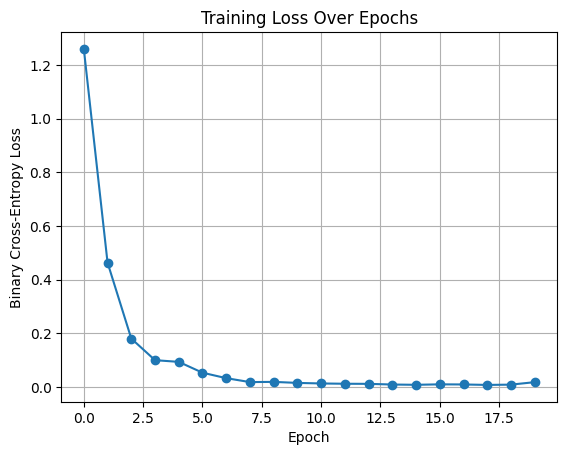

In [72]:
clf = TorchNNClassifier()
clf.fit(X_train, y_train)
plot_loss(clf)

In [73]:
clf.score(X_val, y_val)

=== ADHD Classification Report ===
              precision    recall  f1-score   support

     No ADHD       0.24      0.31      0.27        65
        ADHD       0.72      0.65      0.68       178

    accuracy                           0.56       243
   macro avg       0.48      0.48      0.48       243
weighted avg       0.59      0.56      0.57       243

=== Sex Classification Report ===
              precision    recall  f1-score   support

        Male       0.70      1.00      0.83       171
      Female       0.00      0.00      0.00        72

    accuracy                           0.70       243
   macro avg       0.35      0.50      0.41       243
weighted avg       0.50      0.70      0.58       243



array([[1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [0,

## Notes

Found in notebook "WiDS Datathon 2025| ADHD Prediction"

Conclusion: The one without PCA and UMAP has highest F1 score. This might cause by the loss of important features as they reduce the number of features, which might remove important information that helping XGboost for better predictions.